# Fig. 6 — Socio-ecological scenario outcomes

**Executable research notebook (Python/Matplotlib).** Both panels are generated from explicitly stated equations, not image generation.

- **Fig. 6a:** annual-average tourist admissions under business-as-usual and pricing-plus-growth intervention scenarios.
- **Fig. 6b:** modeled waste generation and handling capacity based on those same annual-average admissions.
- **Observed source baseline:** full-year 2024 Bromo admissions (465,770 domestic + 19,926 international = 485,696, reported by BB TNBTS through ANTARA). 2023 full-year 368,507 is included only as a plotted observation.
- **Reporting distinction:** Annual admissions / calendar days is an *average admissions flow*, **not** instantaneous on-site tourist population.
- **Model status:** scenario assumptions, not validated observations or a reproduction of the original seven stock-flow notebooks. The intervention begins in 2026.

Source reading: [2023 visitor counts](https://www.antaranews.com/berita/3930348/kunjungan-wisatawan-ke-bromo-pada-2023-), [2024 visitor counts](https://www.antaranews.com/berita/4895561/tnbts-memperketat-pengawasan-di-bromo-cegah-masuknya-wisatawan-ilegal), [2024 operational quota](https://www.antaranews.com/berita/4046541/balai-besar-tnbts-belum-tambah-kuota-wisatawan-saat-libur-lebaran).

## 1. Observations and assumptions

All model growth rates, ticket effects, waste coefficients, and management-capacity parameters below are **scenario assumptions**, not measured ecological indicators.

For each year: `BAU(t) = BAU(t−1) × (1 + 0.0468)`. The intervention follows BAU through 2025, then uses `(1 + 0.035)` annual growth from 2026 onward, with one-time price-response multipliers `1 + (−0.504) × 0.08` (domestic) and `1 + (−0.504) × 0.25` (international) in 2026.

For Fig. 6b, waste-generation proxy is `0.5 kg × annual-average admissions`. Management capacity is set at an assumed 1,000 kg/day for BAU and grows by 5% per year for the intervention beginning in 2026. These are **not measured waste quantities**.

In [1]:
from pathlib import Path
from calendar import isleap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from PIL import Image
from IPython.display import display

OUT = Path.cwd()
OBSERVED = {
    2023: {'domestic': 355_297, 'international': 13_210},
    2024: {'domestic': 465_770, 'international': 19_926},
}
OPERATIONAL_REFERENCE = 2_752  # admissions/day, 2024 operational quota; NOT ecological capacity
BAU_ANNUAL_GROWTH = 0.0468
INTERVENTION_ANNUAL_GROWTH = 0.035
PRICE_ELASTICITY_ASSUMPTION = -0.504
DOMESTIC_PRICE_FACTOR = 1.08
FOREIGN_PRICE_FACTOR = 1.25
WASTE_PER_ADMISSION_KG = 0.5  # hypothetical, not observed
BASELINE_HANDLING_KG_PER_DAY = 1_000  # hypothetical, not observed
INTERVENTION_HANDLING_ANNUAL_GROWTH = 0.05
INTERVENTION_START = 2026
START_YEAR, END_YEAR = 2025, 2045

assert sum(OBSERVED[2024].values()) == 485_696
assert sum(OBSERVED[2023].values()) == 368_507
print('2024 annual-average admissions/day:', round(485_696/366, 2))

2024 annual-average admissions/day: 1327.04


In [2]:
# Independently specified annual-mean demand scenario; not original daily tourist stock.
base_dom = OBSERVED[2024]['domestic'] / 366
base_for = OBSERVED[2024]['international'] / 366
bau_dom, bau_for = base_dom, base_for
intervention_dom, intervention_for = base_dom, base_for
records = []
for year in range(START_YEAR, END_YEAR + 1):
    bau_dom *= 1 + BAU_ANNUAL_GROWTH
    bau_for *= 1 + BAU_ANNUAL_GROWTH

    if year == START_YEAR:
        intervention_dom, intervention_for = bau_dom, bau_for
    else:
        intervention_dom *= 1 + INTERVENTION_ANNUAL_GROWTH
        intervention_for *= 1 + INTERVENTION_ANNUAL_GROWTH
        if year == INTERVENTION_START:
            intervention_dom *= 1 + PRICE_ELASTICITY_ASSUMPTION * (DOMESTIC_PRICE_FACTOR - 1)
            intervention_for *= 1 + PRICE_ELASTICITY_ASSUMPTION * (FOREIGN_PRICE_FACTOR - 1)

    demand_bau = bau_dom + bau_for
    demand_intervention = intervention_dom + intervention_for
    years_since_2025 = max(0, year-2025)
    records.append({
        'year': year,
        'bau_annual_mean_admissions_per_day': demand_bau,
        'intervention_annual_mean_admissions_per_day': demand_intervention,
        'bau_waste_proxy_kg_day': demand_bau * WASTE_PER_ADMISSION_KG,
        'intervention_waste_proxy_kg_day': demand_intervention * WASTE_PER_ADMISSION_KG,
        'bau_handling_assumption_kg_day': BASELINE_HANDLING_KG_PER_DAY,
        'intervention_handling_assumption_kg_day': BASELINE_HANDLING_KG_PER_DAY * (1 + INTERVENTION_HANDLING_ANNUAL_GROWTH) ** years_since_2025,
    })

df = pd.DataFrame(records)
first_bau_reference_year = int(df.loc[df['bau_annual_mean_admissions_per_day'] >= OPERATIONAL_REFERENCE, 'year'].iloc[0])
intervention_reaches_reference = bool((df['intervention_annual_mean_admissions_per_day'] >= OPERATIONAL_REFERENCE).any())
assert first_bau_reference_year == 2040
assert not intervention_reaches_reference
assert np.isclose(df.iloc[-1]['bau_annual_mean_admissions_per_day'], 3467.54, atol=0.1)
assert np.isclose(df.iloc[-1]['intervention_annual_mean_admissions_per_day'], 2642.94, atol=0.1)
assert np.isclose(df.iloc[-1]['intervention_handling_assumption_kg_day'], 2653.30, atol=0.1)

df.to_csv(OUT / 'ATR_Fig6_Scenario_Output.csv', index=False, float_format='%.8f')
print('BAU first annual-mean operational-reference year:', first_bau_reference_year)
print('Intervention reaches reference by 2045:', intervention_reaches_reference)
display(df.loc[df.year.isin([2025, 2026, 2040, 2045])].round(2))

BAU first annual-mean operational-reference year: 2040
Intervention reaches reference by 2045: False


,year,bau_annual_mean_admissions_per_day,intervention_annual_mean_admissions_per_day,bau_waste_proxy_kg_day,intervention_waste_proxy_kg_day,bau_handling_assumption_kg_day,intervention_handling_assumption_kg_day
0,2025,1389.14,1389.14,694.57,694.57,1000,1000.00
1,2026,1454.16,1374.74,727.08,687.37,1000,1050.00
15,2040,2758.69,2225.28,1379.34,1112.64,1000,2078.93
20,2045,3467.54,2642.94,1733.77,1321.47,1000,2653.30


## 2. Plotting conventions

Panels are rendered as **two independent Matplotlib plots**, then arranged together into one manuscript figure. Typography and paths are reproducible. All plots depict *modeled or derived* outcomes; no ecological validation is implied.

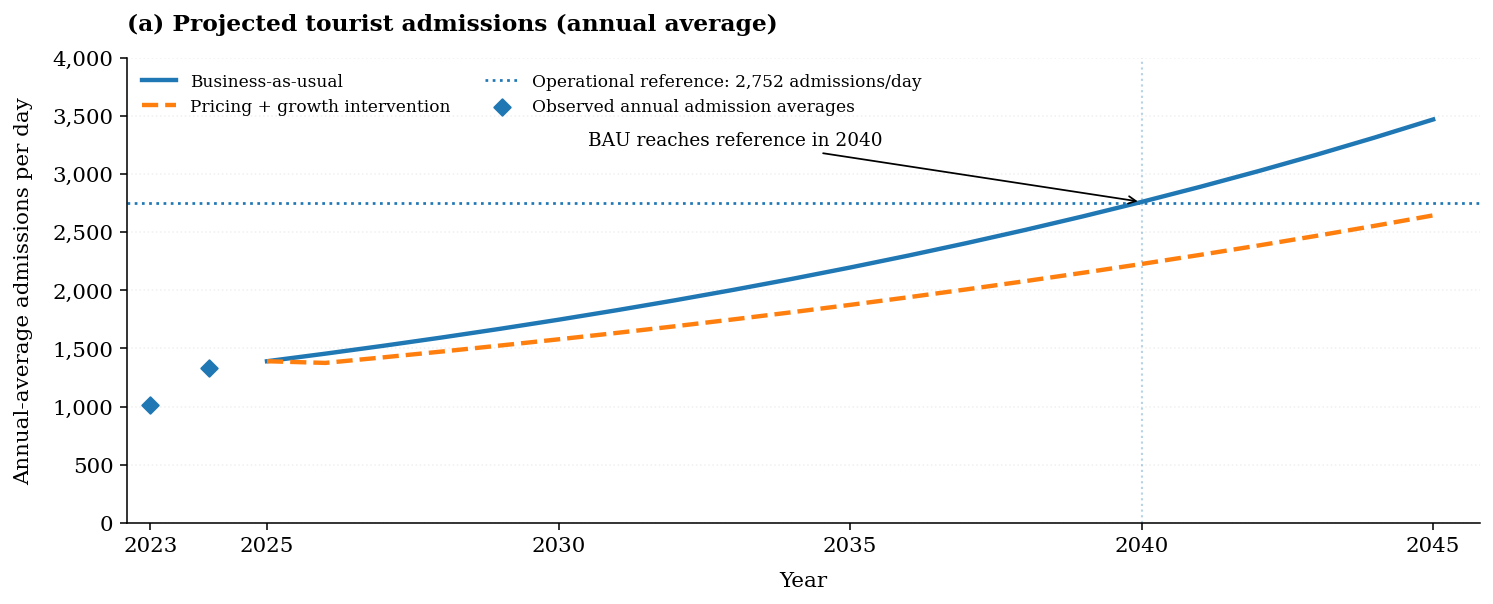

ATR_Fig6a_Admissions_300dpi.png


In [3]:
plt.rcParams.update({
    'font.family': 'DejaVu Serif',
    'font.size': 11,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'figure.dpi': 140,
    'savefig.dpi': 300,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

def format_panel(ax, title, ylabel):
    ax.set_title(title, loc='left', fontweight='bold', pad=14)
    ax.set_ylabel(ylabel, labelpad=10)
    ax.set_xlabel('Year', labelpad=8)
    ax.grid(axis='y', alpha=0.18, linestyle=':')
    ax.set_axisbelow(True)
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax.set_xticks([2023, 2025, 2030, 2035, 2040, 2045])
    ax.set_xlim(2022.6, 2045.8)

fig_a, ax = plt.subplots(figsize=(10.8, 4.45))
ax.plot(df['year'], df['bau_annual_mean_admissions_per_day'],
        linewidth=2.25, label='Business-as-usual')
ax.plot(df['year'], df['intervention_annual_mean_admissions_per_day'],
        linewidth=2.25, linestyle='--', label='Pricing + growth intervention')
ax.axhline(OPERATIONAL_REFERENCE, linewidth=1.4, linestyle=':',
           label='Operational reference: 2,752 admissions/day')
obs_x = [2023, 2024]
obs_y = [sum(OBSERVED[y].values())/(366 if isleap(y) else 365) for y in obs_x]
ax.scatter(obs_x, obs_y, marker='D', s=36, zorder=5,
           label='Observed annual admission averages')
ax.axvline(first_bau_reference_year, linestyle=':', alpha=0.32, linewidth=1.1)
ax.annotate('BAU reaches reference in 2040',
            (2040, df.loc[df.year.eq(2040),'bau_annual_mean_admissions_per_day'].iloc[0]),
            xytext=(2030.5, 3250), fontsize=9.5,
            arrowprops=dict(arrowstyle='->', linewidth=0.9))
format_panel(ax, '(a) Projected tourist admissions (annual average)',
             'Annual-average admissions per day')
ax.set_ylim(0, 4000)
ax.legend(loc='upper left', ncol=2, fontsize=8.75, frameon=False)
fig_a.tight_layout()
path_a = OUT / 'ATR_Fig6a_Admissions_300dpi.png'
fig_a.savefig(path_a, dpi=300, bbox_inches='tight', pad_inches=0.16)
plt.show()
print(path_a.name)

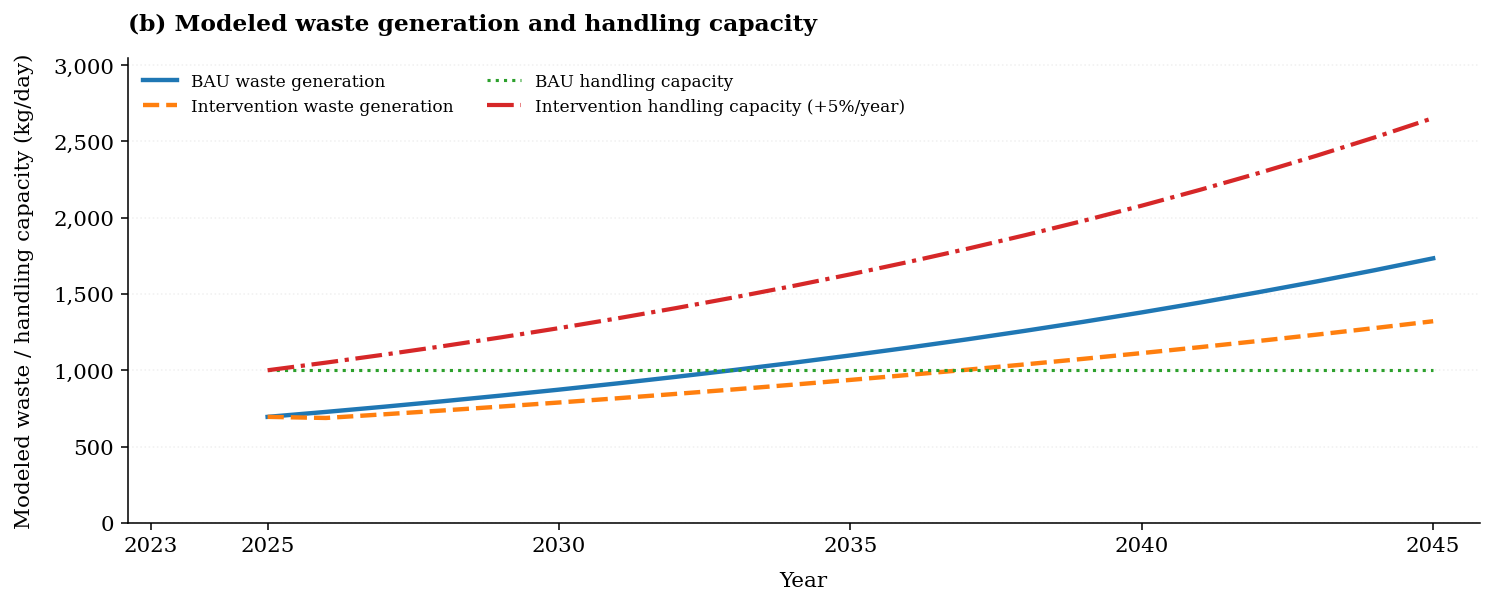

ATR_Fig6b_Waste_300dpi.png


In [4]:
fig_b, ax = plt.subplots(figsize=(10.8, 4.45))
ax.plot(df['year'], df['bau_waste_proxy_kg_day'],
        linewidth=2.25, label='BAU waste generation')
ax.plot(df['year'], df['intervention_waste_proxy_kg_day'],
        linewidth=2.25, linestyle='--', label='Intervention waste generation')
ax.plot(df['year'], df['bau_handling_assumption_kg_day'],
        linewidth=1.6, linestyle=':', label='BAU handling capacity')
ax.plot(df['year'], df['intervention_handling_assumption_kg_day'],
        linewidth=2.15, linestyle='-.', label='Intervention handling capacity (+5%/year)')
format_panel(ax, '(b) Modeled waste generation and handling capacity',
             'Modeled waste / handling capacity (kg/day)')
ax.set_ylim(0, 3050)
ax.legend(loc='upper left', ncol=2, fontsize=8.75, frameon=False)
fig_b.tight_layout()
path_b = OUT / 'ATR_Fig6b_Waste_300dpi.png'
fig_b.savefig(path_b, dpi=300, bbox_inches='tight', pad_inches=0.16)
plt.show()
print(path_b.name)

Saved combined Fig. 6: ATR_Fig6_Socioecological_Executed_300dpi.png | dimensions: (3243, 2718)


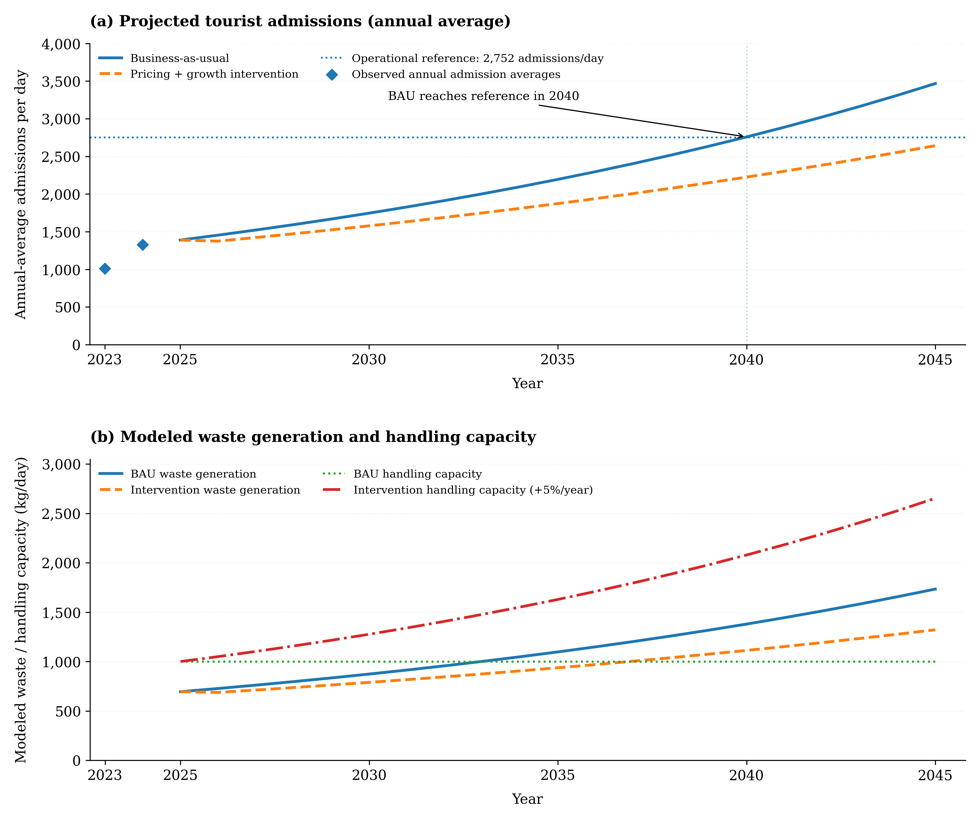

In [5]:
# Stitch the two independently saved plots into a single two-panel manuscript image.
with Image.open(path_a) as first, Image.open(path_b) as second:
    first = first.convert('RGB')
    second = second.convert('RGB')
    width = max(first.width, second.width)
    padding = 34
    combined = Image.new('RGB', (width, first.height + second.height + padding), 'white')
    combined.paste(first, ((width-first.width)//2, 0))
    combined.paste(second, ((width-second.width)//2, first.height+padding))
    figure_path = OUT / 'ATR_Fig6_Socioecological_Executed_300dpi.png'
    combined.save(figure_path, dpi=(300, 300), optimize=True)

print('Saved combined Fig. 6:', figure_path.name, '| dimensions:', combined.size)
display(combined.resize((980, round(combined.height * 980/combined.width))))

## 3. Reproducibility notes

**Caption for manuscript:** **Fig. 6.** Socio-ecological scenario outcomes: (a) projected annual-average tourist admissions and (b) modeled waste generation and handling capacity.

**Calculation boundary:** Results are from this separately specified annual-average scenario. In panel (b), waste volumes are a rate-derived proxy (admissions × 0.5 kg/admission), and handling capacity is based on assumed 1,000 kg/day baseline and 5% annual intervention growth. They are not observed field waste data or replicated outputs from the legacy daily environmental-sanitation notebook. **Do not attribute the result to a validated, fully coupled seven-subsystem simulation.**

The figures and the CSV can be regenerated by executing all cells in this notebook in Google Colab or Jupyter.